# MSc Final Project — Visible In-Progress (VIP) notebook

| | |
|---|---|
| **Project title** | Detecting Tuberculosis in Chest X-rays with Numerical Image Features and Classical Machine Learning: A Within- and Cross-Dataset Study on the Montgomery and Shenzhen Sets |
| **Student name / number** | Izuchukwu D. Agballah, 24136661 |
| **Supervisor** | Muhammad Yaqoob |
| **GitHub repository** | https://github.com/Izuchukwu-A/msc-project-agballah |
| **Overleaf project** | *link to your IPR/FPR Overleaf project* |
| **Ethics approval** | Not required — both datasets are public, de-identified releases from the US National Library of Medicine (no new data collection, no personal data) |

This notebook is my **practical work**: data, artefact, experiments and results. The **report** (IPR 10%, FPR 70%) is written in the Overleaf template. The **demo/viva (20%)** is run from this notebook.

**How this notebook is organised.** All the code is in the `tb_ml/` folder: one file that turns an X-ray into 13 numbers (`features.py`), one file with the two models (`models.py`) and four numbered scripts (`step0`–`step4`). Each section below runs one script and shows what it produced.

The first version (deep learning, U-Net lung masks, intensity corrections, bootstrap and DeLong tests) was too advanced. Following my supervisor's advice, the project now extracts **numerical features** from each X-ray and classifies them with two simple, well-understood models from the literature: a **Decision Tree** and a **Support Vector Machine (SVM)**.

**Status at week 10.**

| Phase | Weeks | Work | Status |
|---|---|---|---|
| 1 | 1–2 | Literature review and proposal | ✅ done |
| 2 | 3–4 | Data download, verification, inspection | ✅ done |
| 3 | 5–9 | First pipeline (deep learning) | replaced after IPR feedback |
| 4 | 9–10 | Feature extraction, Decision Tree and SVM, repeated cross-validation | ✅ done |
| 5 | 10 | Feature-group and cross-dataset experiments | ✅ done |
| 6 | 10–11 | Reading (two papers a week), discussion, limitations | in progress |
| 7 | 11–12 | FPR write-up, GitHub release, demo | planned |

### Working method (git)

1. **Supervisor is a collaborator** on the GitHub repo (Settings → Collaborators).
2. **Commit and push after every task and every change.** The history shows how the project developed.
   ```bash
   git status
   git add .
   git commit -m "CODE: what you did"
   git push
   ```
3. Start each commit message with the part worked on: `DATA:` · `CODE:` · `EXP:` · `TEST:` · `RESULT:` · `FIX:` · `LIT:`
   e.g. `EXP: repeated 5-fold CV for Decision Tree and SVM`
4. The images (`tb_ml/data/raw/`) and the Python environment (`tb_ml/.venv/`) are **git-ignored** — they are never committed.
5. **Before each supervision meeting, push the latest work** so the supervisor reviews what changed.

### Working on a branch

A branch lets me build one part without breaking the working version on `main`.

**1. Create a branch and work on it**
```bash
git checkout -b feature-groups
git add .
git commit -m "EXP: feature-group experiment (intensity / texture / edges)"
git push -u origin feature-groups
```
**2. When the part works, merge it into `main`**
```bash
git checkout main
git merge feature-groups
git push
```
`git branch` shows the current branch (marked `*`). On GitHub the supervisor can see every branch and its commits.

# 1. Imports and environment
*Project set-up.* The code runs in its own virtual environment, `tb_ml/.venv`. Select the kernel **Python (tb_ml .venv)** at the top right of this notebook. First time on a new computer, run this in a terminal inside `tb_ml`:
```powershell
python -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt ipykernel
python -m ipykernel install --user --name tb-ml-venv --display-name "Python (tb_ml .venv)"
```

In [1]:
import os, sys
from pathlib import Path

# Find the tb_ml folder whether the notebook is opened from the project root or from tb_ml itself.
HERE = Path.cwd()
TB_ML = next(p for p in [HERE / "tb_ml", HERE, *HERE.parents] if (p / "features.py").exists() and (p / "models.py").exists())
os.chdir(TB_ML)
if str(TB_ML) not in sys.path:
    sys.path.insert(0, str(TB_ML))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from features import FEATURE_NAMES, FEATURE_GROUPS, extract_features, load_image
from models import SEED, make_models, mean_std_table

RAW = TB_ML / "data" / "raw"
RESULTS = TB_ML / "results"

# RERUN = False reuses finished results so "Run All" takes seconds.
# Set it to True to recompute everything (about 10 minutes on a laptop CPU).
RERUN = False

def step(script, done):
    """Run a tb_ml script, unless its output file already exists and RERUN is False."""
    if not RERUN and Path(done).exists():
        print(f"[skip] {script} - already done -> {Path(done).relative_to(TB_ML)}  (set RERUN = True to redo)")
        return
    get_ipython().run_line_magic("run", script)

print("tb_ml folder:", TB_ML)
print("seed:", SEED, "| RERUN:", RERUN)

tb_ml folder: c:\Users\harip\OneDrive\Pictures\Derick\tb_cross_dataset_code_week9\tb_ml
seed: 42 | RERUN: False


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: tb_ml environment and notebook set-up"
git push
```

# 2. Research question and objectives

**Problem.** Tuberculosis is usually first screened with a chest X-ray, but the countries with the most TB have the fewest radiologists. An automated reader could help flag likely TB cases.

**Aim.** Find out how well TB can be detected from a small set of numerical features extracted from each chest X-ray, using two classical machine learning models — a Decision Tree and an SVM — and whether a model trained on one hospital's images works on the other's.

**Research questions.**
1. How accurately can a Decision Tree and an SVM detect TB from 13 numerical image features, within each dataset?
2. Which of the two models performs better, and why?
3. Which feature group (intensity, texture or edges) is most useful?
4. How much does performance drop when a model trained on one hospital is tested on the other?

**Objectives.**
1. Review the literature on numerical feature extraction from chest X-rays and the models used with these features.
2. Download both datasets, verify the counts, and check for duplicate images.
3. Extract 13 features (6 intensity, 5 GLCM texture, 2 edge) from every image.
4. Evaluate a Decision Tree and an SVM with repeated stratified 5-fold cross-validation (mean ± std over 25 test folds).
5. Compare the feature groups, run the cross-dataset test in both directions, and compare with Jaeger et al. (2014).

# 3. Data
*FPR: Methodology — data.*

**Source and licence.** Two public chest X-ray sets released by the US National Library of Medicine (Jaeger et al., 2014): **Montgomery County, USA** (138 images: 58 TB, 80 normal) and **Shenzhen, China** (662 images: 336 TB, 326 normal). Free for research use.

**Ethics / GDPR.** Both sets are de-identified and public; no new data is collected, so no ethics approval is required. Images live under `tb_ml/data/raw/` and are **git-ignored**.

`step0_download_data.py` downloads both sets (about 4 GB; only needed once). The label is the last digit of each filename: `_0` normal, `_1` TB.

In [2]:
# Download the data if it is not there yet (skipped when the images are already on disk)
step("step0_download_data.py", RAW / "ChinaSet_AllFiles" / "CXR_png" / "CHNCXR_0662_1.png")

rows = []
for dataset, folder in [("montgomery", "MontgomerySet"), ("shenzhen", "ChinaSet_AllFiles")]:
    for p in sorted((RAW / folder / "CXR_png").glob("*.png")):
        rows.append({"dataset": dataset, "image_id": p.stem, "label": int(p.stem[-1])})
images = pd.DataFrame(rows)
counts = images.groupby(["dataset", "label"]).size().unstack().rename(columns={0: "normal", 1: "TB"})
counts["total"] = counts.sum(axis=1)
counts

[skip] step0_download_data.py - already done -> data\raw\ChinaSet_AllFiles\CXR_png\CHNCXR_0662_1.png  (set RERUN = True to redo)


label,normal,TB,total
dataset,,,
montgomery,80,58,138
shenzhen,326,336,662


### Data-quality check and cleaning log

| Step | What I checked / found | What I did | Why |
|---|---|---|---|
| 1 | Counts against the published figures | Montgomery 58 TB / 80 normal, Shenzhen 336 TB / 326 normal — match | Make sure the download is complete |
| 2 | File formats differ: Montgomery is 8-bit greyscale, Shenzhen is palette or RGB PNG | Convert every image to 8-bit greyscale | One intensity scale for both sets |
| 3 | Images are different sizes (about 4020×4892 and 3000×3000) | Resize every image to 256×256 | Features must be computed on the same image size |
| 4 | Duplicate images (cell below) | None found — no identical files, no near-identical images | The same X-ray must not be in both a training and a test fold |
| 5 | Montgomery images have black borders and text labels ("PA ERECT") | Kept, and recorded as a limitation | These are hospital differences, not disease |

In [3]:
# Duplicate check: exact copies (same file hash) and near-copies (same picture, slightly different bytes)
import hashlib
from PIL import Image as PILImage

paths = sorted(RAW.glob("*/CXR_png/*.png"))
hashes = pd.Series([hashlib.md5(p.read_bytes()).hexdigest() for p in paths])
print("images:", len(paths), "| exact duplicates:", int(hashes.duplicated().sum()))

# Near-duplicates: compare 64x64 thumbnails of every pair of images (correlation 1.0 = identical picture)
thumbs = np.array([np.asarray(PILImage.open(p).convert("L").resize((64, 64)), dtype=float).ravel() for p in paths])
thumbs = (thumbs - thumbs.mean(axis=1, keepdims=True)) / thumbs.std(axis=1, keepdims=True)
corr = thumbs @ thumbs.T / thumbs.shape[1]
np.fill_diagonal(corr, 0)
print("near-duplicate pairs (correlation > 0.98):", int((np.triu(corr) > 0.98).sum()))
print("most similar pair: correlation", round(float(corr.max()), 3))

images: 800 | exact duplicates: 0
near-duplicate pairs (correlation > 0.98): 0
most similar pair: correlation 0.966


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "DATA: datasets verified, cleaning log and duplicate check"
git push
```

# 4. Feature extraction and exploratory analysis
*FPR: Methodology — features.*

Every image is turned into **13 numbers** (`features.py`):

| Group | Features | What they measure |
|---|---|---|
| Intensity (6) | mean, median, std, skewness, kurtosis, entropy | Brightness and the shape of the grey-level histogram |
| Texture (5) | GLCM contrast, dissimilarity, homogeneity, energy, correlation | How neighbouring pixels relate: smooth vs patchy (Haralick et al., 1973) |
| Edges (2) | mean and std of the Sobel gradient | How many sharp brightness changes there are |

**GLCM** (grey-level co-occurrence matrix): the image is reduced to 32 grey levels; the GLCM counts how often grey level *i* sits next to grey level *j*, one pixel apart, in four directions (0°, 45°, 90°, 135°). Each texture feature summarises that matrix, averaged over the directions. TB lesions make the lung texture patchier, which changes these numbers.

In [4]:
# step1_extract_features.py: 13 features for all 800 images -> results/features.csv (a few minutes)
step("step1_extract_features.py", RESULTS / "features.csv")
features = pd.read_csv(RESULTS / "features.csv")
print("feature table:", features.shape)
features.head()

[skip] step1_extract_features.py - already done -> results\features.csv  (set RERUN = True to redo)
feature table: (800, 16)


,image_id,dataset,label,mean,std,skewness,kurtosis,entropy,median,glcm_contrast,glcm_dissimilarity,glcm_homogeneity,glcm_energy,glcm_correlation,edge_mean,edge_std
0,MCUCXR_0001_0,montgomery,0,116.548630,86.793393,0.068880,-1.406075,7.170152,114.0,3.368731,0.597311,0.788286,0.207231,0.985429,0.030545,0.063029
1,MCUCXR_0002_0,montgomery,0,133.536789,78.116192,0.036562,-1.230509,7.772890,130.0,1.904507,0.566515,0.779051,0.143925,0.989964,0.027923,0.041016
2,MCUCXR_0003_0,montgomery,0,146.210678,82.117650,-0.332580,-1.221397,7.601231,163.0,4.070019,0.660401,0.772290,0.160330,0.980435,0.033520,0.068828
3,MCUCXR_0004_0,montgomery,0,84.104294,89.210760,0.494770,-1.329008,5.788478,54.0,3.150777,0.576322,0.812594,0.424697,0.986968,0.029353,0.061821
4,MCUCXR_0005_0,montgomery,0,112.281433,80.063944,0.146587,-1.269248,7.312281,103.0,3.379307,0.635992,0.778820,0.177037,0.982840,0.031664,0.061758


In [5]:
# The same thing for one image, so you can see exactly what the model receives
example = RAW / "ChinaSet_AllFiles" / "CXR_png" / "CHNCXR_0327_1.png"
pd.Series(extract_features(example), name=example.stem).round(4).to_frame()

,CHNCXR_0327_1
mean,147.3635
std,61.5174
skewness,-0.5629
kurtosis,-0.5865
entropy,7.5966
median,156.0000
glcm_contrast,1.5098
glcm_dissimilarity,0.7329
glcm_homogeneity,0.6988
glcm_energy,0.1270


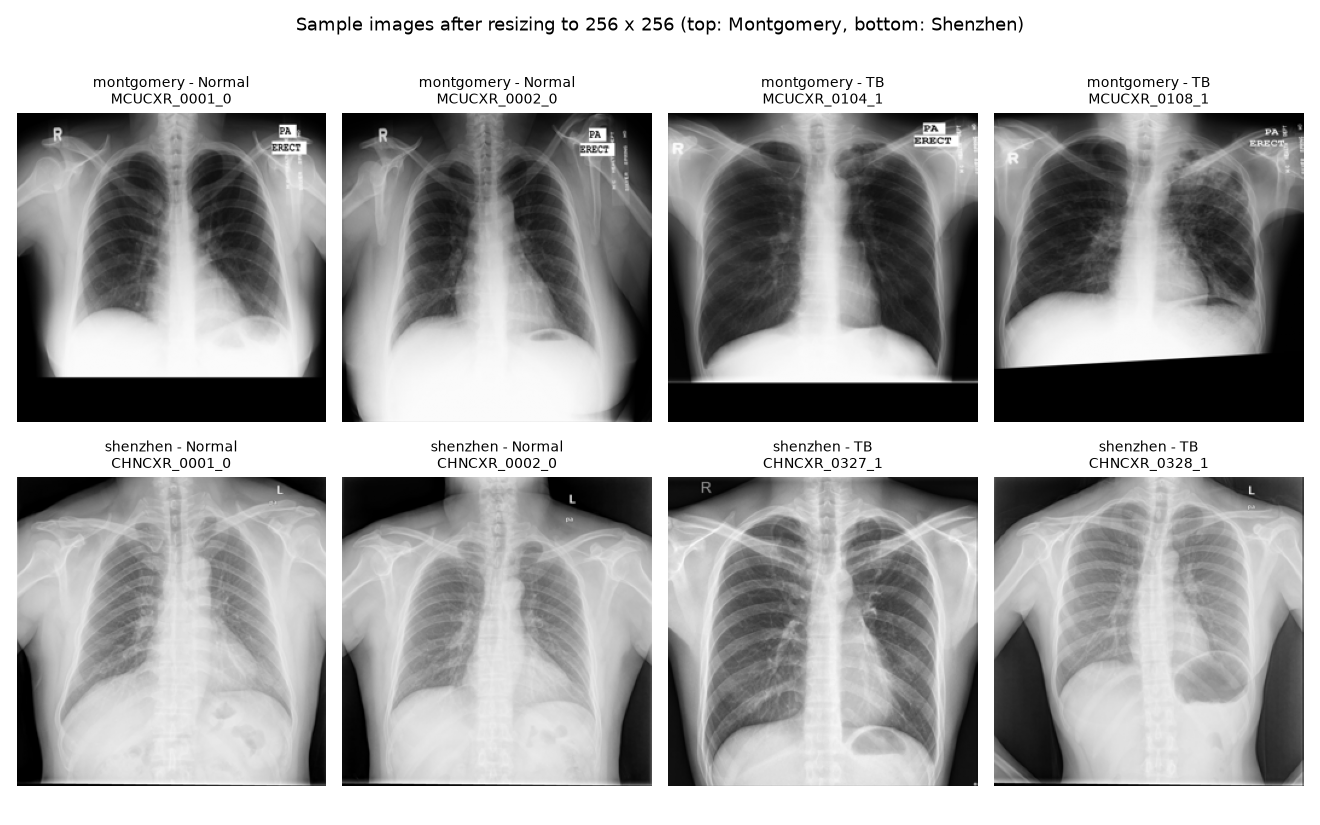

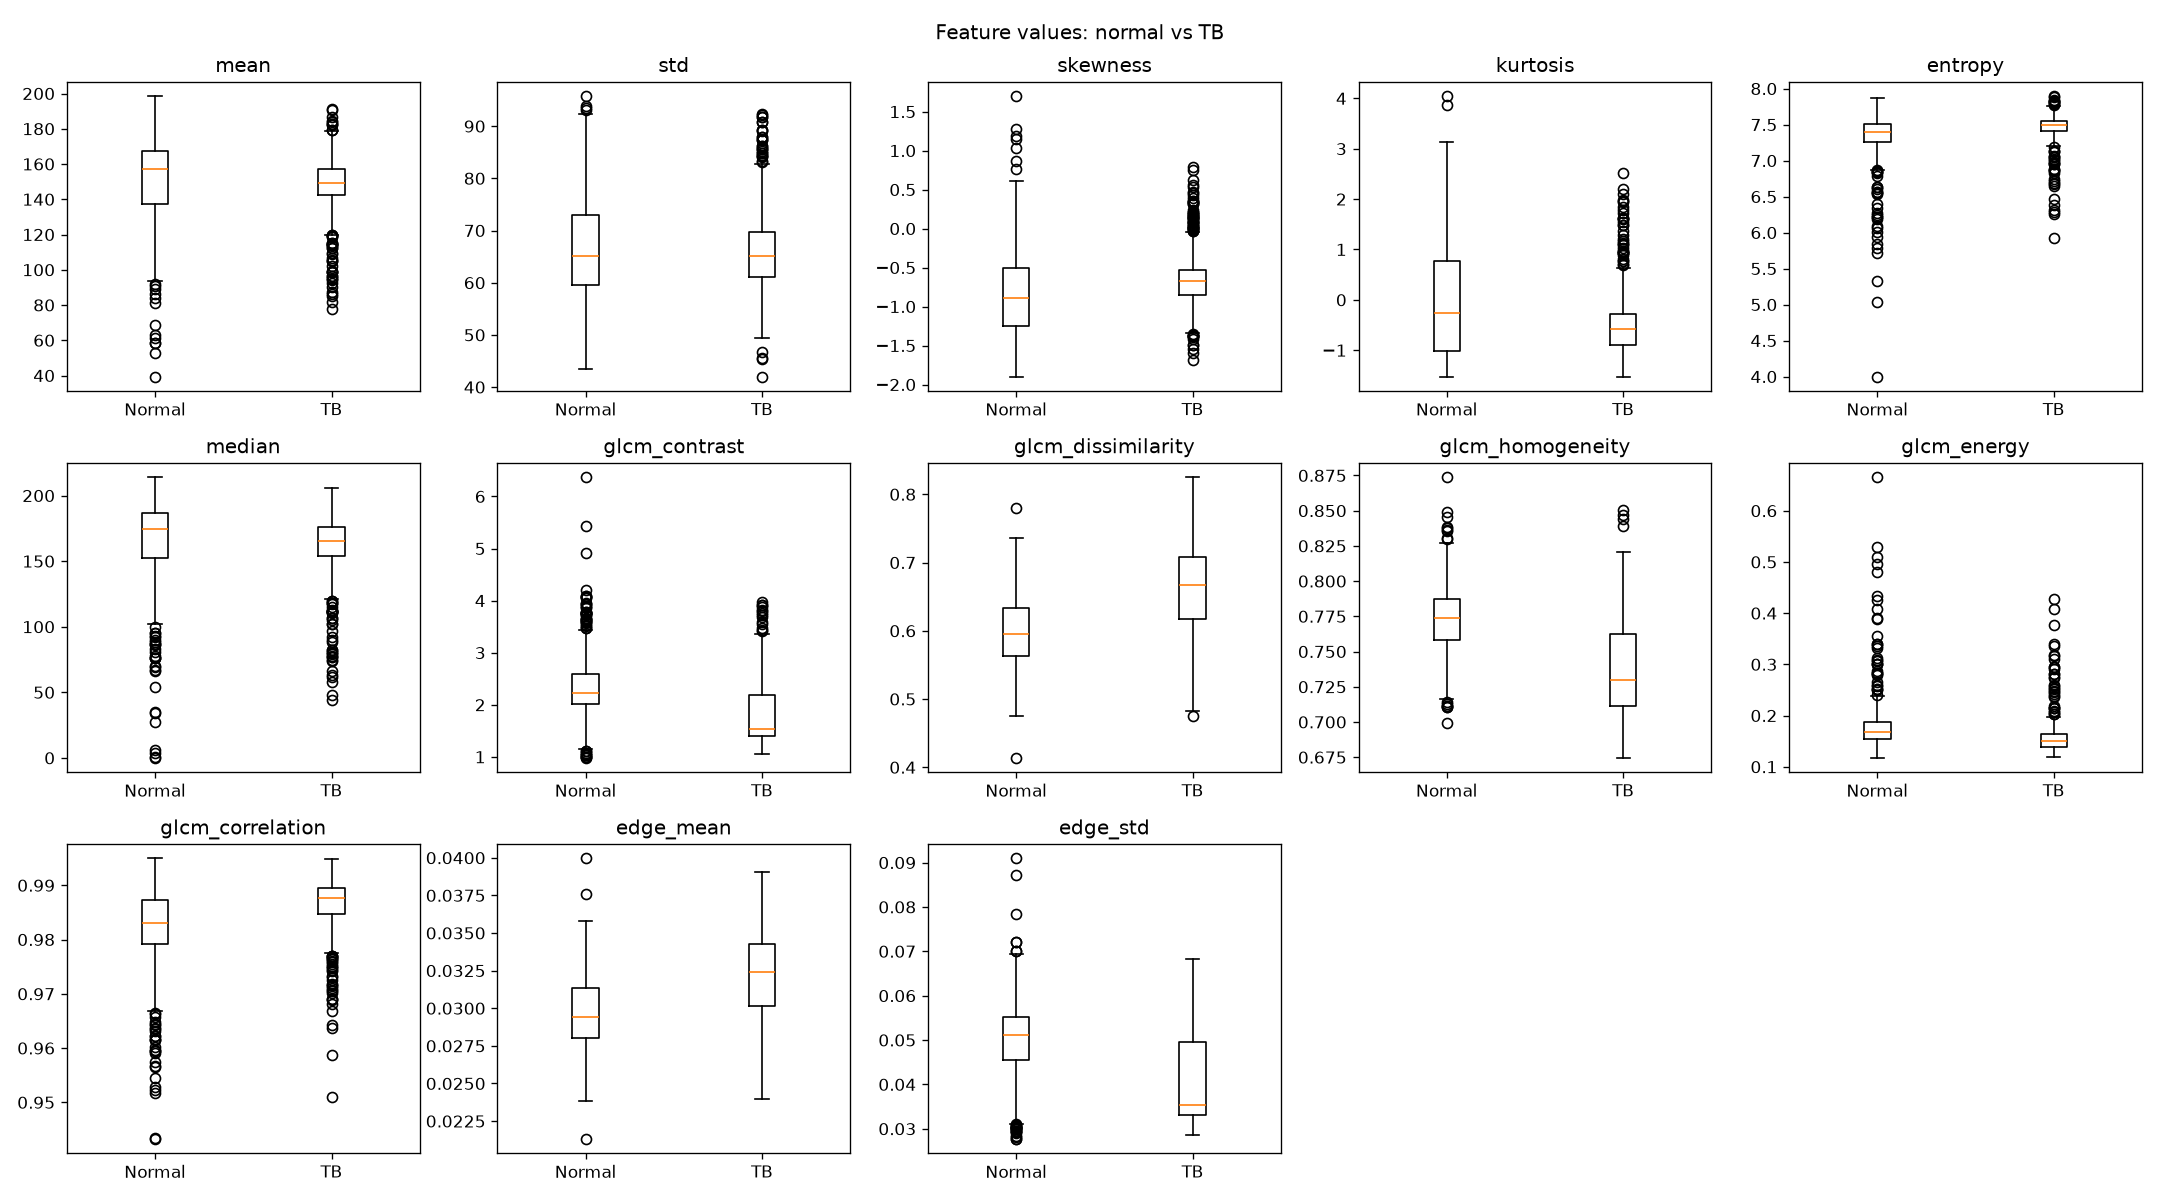

In [6]:
display(Image(filename=str(RESULTS / "sample_images.png")))
display(Image(filename=str(RESULTS / "feature_boxplots.png")))

*What did I learn, and how does it affect the method?* The two hospitals' images look different: Montgomery has wide black borders and burned-in text labels, Shenzhen is framed tightly. Whole-image features will pick up these differences as well as disease, which is why the cross-dataset test (section 6) matters. In the box plots, several texture and edge features differ clearly between normal and TB images, so the features do carry a signal. No single feature separates the classes on its own, so a model that combines them is needed.

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: 13 numerical features extracted, sample images and box plots"
git push
```

# 5. Method: the two models
*FPR: Methodology — models.* Both are standard classifiers for hand-crafted features in the TB literature: Jaeger et al. (2014) used an **SVM**; tree-based models (decision trees, random forests) are used by Santosh and Antani (2018) and others.

**Decision Tree** (`models.py`). Asks a series of yes/no questions about the features (e.g. *"is glcm_contrast > 12.3?"*) and follows the answers to a leaf that says Normal or TB. Each question is chosen to best separate the classes (lowest **Gini impurity**). `max_depth` limits how many questions it can ask, so it does not memorise the training images.

**SVM** (`models.py`). Finds the boundary between Normal and TB that leaves the **widest margin** to the nearest images of each class. The RBF kernel lets the boundary curve. `C` trades a wide margin against classifying every training image correctly; `gamma` sets how curved the boundary can be. Features are first scaled to mean 0, std 1 (`StandardScaler`), because the SVM measures distances.

**Evaluation: repeated stratified 5-fold cross-validation.** Each dataset is split into 5 parts with the same TB/normal ratio; each part is the test set once; this is repeated 5 times with different shuffles → **25 test results**, reported as mean ± std. Inside each training part, settings are chosen by another 5-fold cross-validation, so the test part is never used to choose settings. (A single 80/20 split was rejected: on Montgomery it leaves only 28 test images, and one image moves accuracy by about 4%.)

**Metrics** (TB = positive): accuracy; **sensitivity** = TB patients found; **specificity** = healthy patients correctly cleared; precision; F1; **AUC** = chance that a random TB image scores higher than a random normal image (0.5 = guessing, 1 = perfect).

In [7]:
# The two models and the settings tried for each
for name, (model, grid) in make_models().items():
    print(f"{name}:\n  model: {model}\n  settings tried: {grid}\n")

DecisionTree:
  model: DecisionTreeClassifier(random_state=42)
  settings tried: {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [1, 5, 10]}

SVM:
  model: Pipeline(steps=[('scale', StandardScaler()), ('svm', SVC(random_state=42))])
  settings tried: {'svm__C': [0.1, 1, 10, 100], 'svm__gamma': ['scale', 0.01, 0.1]}



Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: Decision Tree and SVM with settings chosen by cross-validation"
git push
```

# 6. Experiments
*FPR: Quality and Results.*

### Experiment 1 — within each dataset (RQ1, RQ2)
`step2_train_models.py`: both models, both datasets, repeated 5-fold cross-validation.

[skip] step2_train_models.py - already done -> results\within_dataset_metrics.csv  (set RERUN = True to redo)


,dataset,model,accuracy,sensitivity,specificity,precision,f1,auc
0,montgomery,DecisionTree,0.561 ± 0.068,0.398 ± 0.210,0.680 ± 0.154,0.482 ± 0.159,0.409 ± 0.144,0.548 ± 0.080
1,montgomery,SVM,0.616 ± 0.062,0.411 ± 0.205,0.765 ± 0.147,0.510 ± 0.230,0.440 ± 0.190,0.655 ± 0.076
2,shenzhen,DecisionTree,0.772 ± 0.036,0.734 ± 0.063,0.812 ± 0.070,0.805 ± 0.056,0.766 ± 0.039,0.827 ± 0.033
3,shenzhen,SVM,0.784 ± 0.034,0.733 ± 0.050,0.837 ± 0.060,0.825 ± 0.051,0.775 ± 0.036,0.860 ± 0.038


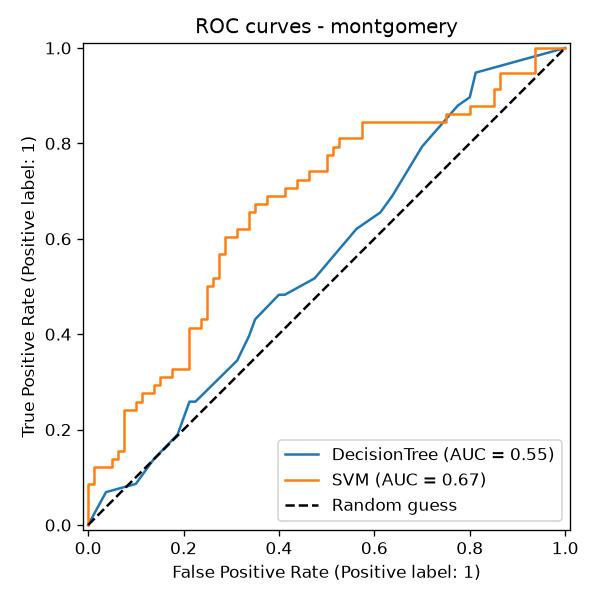

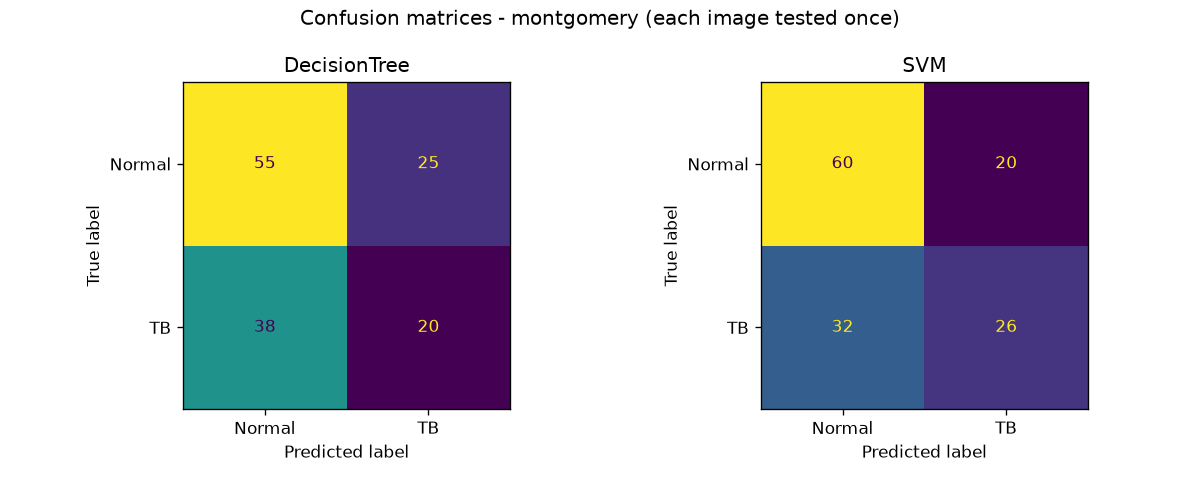

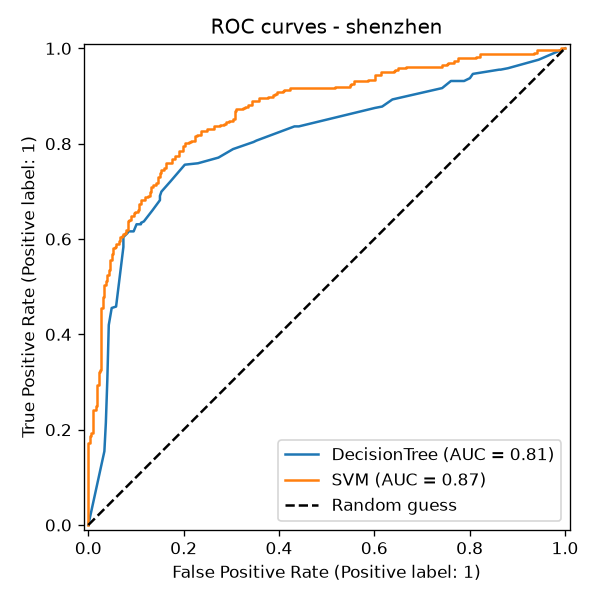

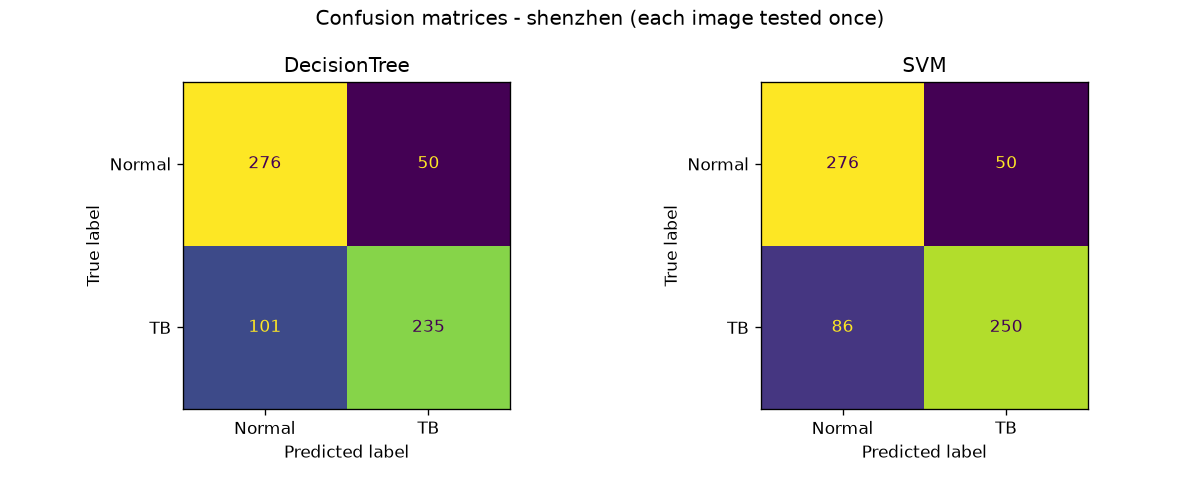

In [8]:
step("step2_train_models.py", RESULTS / "within_dataset_metrics.csv")
within = pd.read_csv(RESULTS / "within_dataset_metrics.csv")
display(mean_std_table(within, ["dataset", "model"]))
for dataset in ["montgomery", "shenzhen"]:
    display(Image(filename=str(RESULTS / f"roc_{dataset}.png"), width=420))
    display(Image(filename=str(RESULTS / f"confusion_{dataset}.png"), width=650))

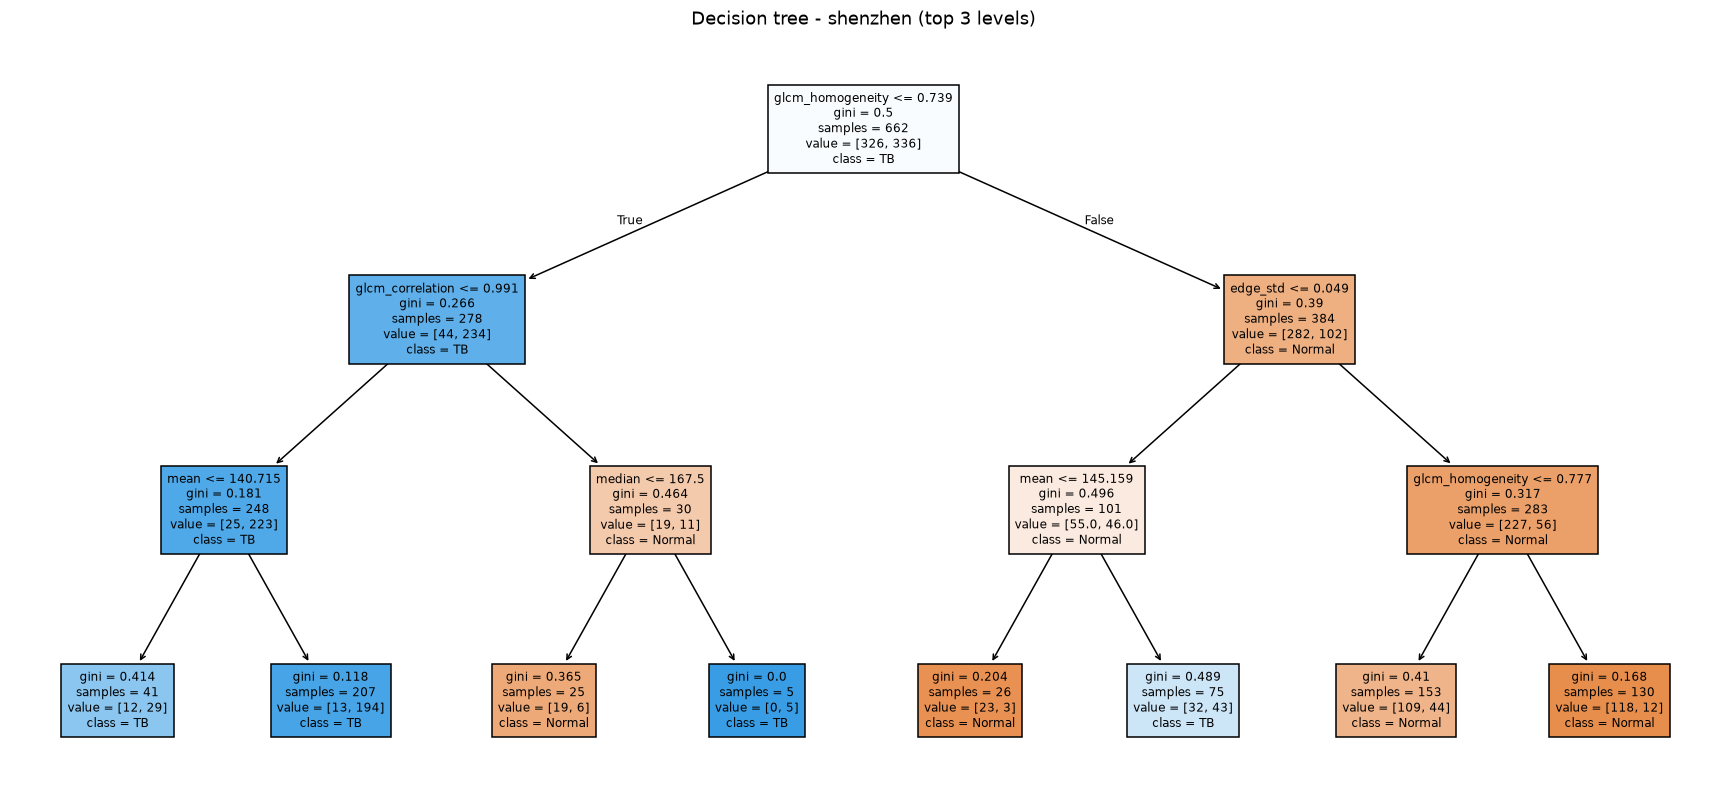

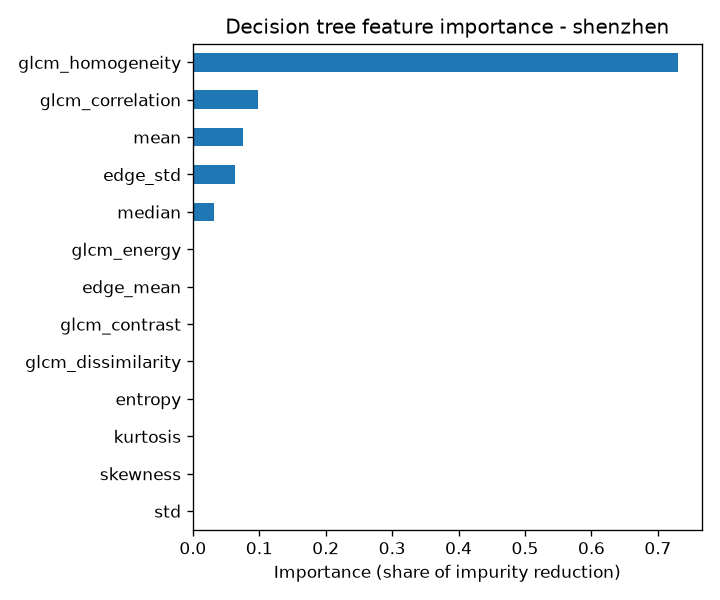

In [9]:
# What the Decision Tree learned on Shenzhen: the top of the tree and which features it used
display(Image(filename=str(RESULTS / "tree_shenzhen.png")))
display(Image(filename=str(RESULTS / "tree_importance_shenzhen.png"), width=480))

### Experiment 2 — train on one hospital, test on the other (RQ4)
`step3_cross_dataset.py`: train on all images of one set, test once on all images of the other, both directions.

In [10]:
step("step3_cross_dataset.py", RESULTS / "cross_dataset_metrics.csv")
cross = pd.read_csv(RESULTS / "cross_dataset_metrics.csv")
cross[["train", "test", "model", "accuracy", "sensitivity", "specificity", "f1", "auc", "tp", "fn", "tn", "fp"]]

[skip] step3_cross_dataset.py - already done -> results\cross_dataset_metrics.csv  (set RERUN = True to redo)


,train,test,model,accuracy,sensitivity,specificity,f1,auc,tp,fn,tn,fp
0,shenzhen,montgomery,DecisionTree,0.580,0.052,0.962,0.094,0.535,3,55,77,3
1,shenzhen,montgomery,SVM,0.580,0.000,1.000,0.000,0.468,0,58,80,0
2,montgomery,shenzhen,DecisionTree,0.492,0.000,1.000,0.000,0.557,0,336,326,0
3,montgomery,shenzhen,SVM,0.731,0.565,0.902,0.681,0.825,190,146,294,32


### Experiment 3 — which feature group matters (RQ3)
`step4_feature_groups.py`: both models on intensity only, texture only, edges only, and all 13 features.

[skip] step4_feature_groups.py - already done -> results\feature_groups_metrics.csv  (set RERUN = True to redo)


group                        intensity        texture          edges  \
dataset    model                                                       
montgomery DecisionTree  0.547 ± 0.088  0.513 ± 0.087  0.583 ± 0.099   
           SVM           0.657 ± 0.096  0.602 ± 0.075  0.610 ± 0.085   
shenzhen   DecisionTree  0.723 ± 0.045  0.819 ± 0.038  0.811 ± 0.041   
           SVM           0.806 ± 0.036  0.845 ± 0.037  0.814 ± 0.033   

group                              all  
dataset    model                        
montgomery DecisionTree  0.548 ± 0.080  
           SVM           0.655 ± 0.076  
shenzhen   DecisionTree  0.827 ± 0.033  
           SVM           0.860 ± 0.038

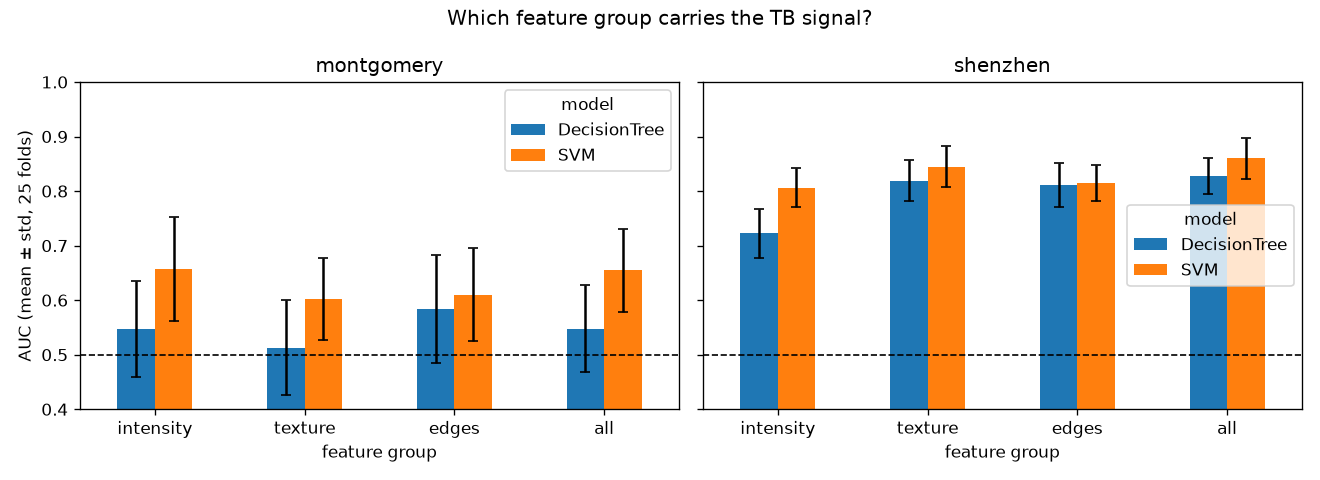

In [11]:
step("step4_feature_groups.py", RESULTS / "feature_groups_metrics.csv")
groups = pd.read_csv(RESULTS / "feature_groups_metrics.csv")
auc = groups.assign(AUC=groups.auc_mean.map("{:.3f}".format) + " ± " + groups.auc_std.map("{:.3f}".format))
display(auc.pivot_table(index=["dataset", "model"], columns="group", values="AUC", aggfunc="first")[list(FEATURE_GROUPS)])
display(Image(filename=str(RESULTS / "feature_groups_auc.png")))

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "EXP: within-dataset, cross-dataset and feature-group experiments"
git push
```

# 7. Testing and validation
*FPR: Methodology — test strategy and validation.*

- **Checks on the data and features** (cell below): counts match the published figures, every image has 13 finite feature values, and feature extraction gives the same numbers when run twice.
- **No leakage:** in every cross-validation fold, the training and test images are different, and settings are chosen on the training part only.
- **Reliable estimates:** 25 test folds with the spread reported, instead of one lucky or unlucky split.
- **Reproducible:** fixed seed (42); every script can be re-run from the raw images.

In [12]:
from sklearn.model_selection import RepeatedStratifiedKFold

# 1. counts match the published figures
assert counts.loc["montgomery", "TB"] == 58 and counts.loc["montgomery", "normal"] == 80
assert counts.loc["shenzhen", "TB"] == 336 and counts.loc["shenzhen", "normal"] == 326

# 2. every image has 13 finite feature values
assert len(features) == 800 and np.isfinite(features[FEATURE_NAMES].to_numpy()).all()

# 3. feature extraction is deterministic: same image -> same numbers
row = features.set_index("image_id").loc[example.stem, FEATURE_NAMES].to_numpy(dtype=float)
assert np.allclose(row, list(extract_features(example).values()))

# 4. no image is in both the training and the test part of any fold
y = features[features.dataset == "montgomery"].label.to_numpy()
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
for train_idx, test_idx in cv.split(np.zeros(len(y)), y):
    assert set(train_idx).isdisjoint(test_idx)

print("All checks passed.")

All checks passed.


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "TEST: data, feature and cross-validation checks"
git push
```

# 8. Results so far (week 10)
*Interim results — not final. Mean ± std over 25 test folds; seed 42.*

**RQ1/RQ2 — within each dataset.**

| Dataset | Model | AUC | Accuracy | Sensitivity | Specificity |
|---|---|---|---|---|---|
| Montgomery | Decision Tree | 0.548 ± 0.080 | 0.561 ± 0.068 | 0.398 ± 0.210 | 0.680 ± 0.154 |
| Montgomery | SVM | 0.655 ± 0.076 | 0.616 ± 0.062 | 0.411 ± 0.205 | 0.765 ± 0.147 |
| Shenzhen | Decision Tree | 0.827 ± 0.033 | 0.772 ± 0.036 | 0.734 ± 0.063 | 0.812 ± 0.070 |
| Shenzhen | SVM | 0.860 ± 0.038 | 0.784 ± 0.034 | 0.733 ± 0.050 | 0.837 ± 0.060 |

The SVM beats the Decision Tree on both datasets. Shenzhen works well; Montgomery (138 images, about 110 per training fold) is much harder, and its results vary a lot between folds.

**RQ3 — feature groups.** On Shenzhen, the 5 texture features alone reach AUC 0.845 with the SVM, almost as good as all 13 (0.860); the 2 edge features reach 0.814; intensity is the weakest group. On Montgomery no group clearly stands out.

**RQ4 — cross-dataset.** In three of the four cases the model collapses to predicting "normal" for almost every image (AUC 0.47–0.56; e.g. Shenzhen → Montgomery SVM finds 0 of 58 TB cases). Only Montgomery → Shenzhen with the SVM holds up (AUC 0.825). Whole-image features capture differences between the hospitals (borders, labels, exposure) as well as disease.

**Comparison with published work.** Jaeger et al. (2014) reported AUC 0.87 (Montgomery) and 0.90 (Shenzhen) with features computed inside segmented lungs and a much larger feature set. This project is within about 0.04 on Shenzhen but far below on Montgomery: whole-image features, 13 features instead of many, and a very small dataset.

**Next.** Read two papers a week and add them to the Excel sheet; write the discussion and limitations; agree with my supervisor whether to add a random forest.

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "RESULT: week-10 results, feature groups and cross-dataset findings"
git push
```